Question 14:  Image Generation using Stable Diffusion: Use Hugging Face’s Diffusers library or InvokeAI to generate images from text prompts. Modify prompts and analyze model creativity and limitations. 

2026-11-07 16:28:24.353260: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794049104.389399  168252 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794049104.400507  168252 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794049104.428803  168252 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794049104.428828  168252 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794049104.428833  168252 computation_placer.cc:177] computation placer alr

model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/722 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/755 [00:00<?, ?B/s]

... (15 outputs left out)

[W1107 16:31:23.718394157 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:31:23.719023282 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.


Generating real image for prompt: 'A realistic photograph of a cup of ...'


  0%|          | 0/15 [00:00<?, ?it/s]

[W1107 16:32:40.473071426 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 16:32:40.473621662 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.


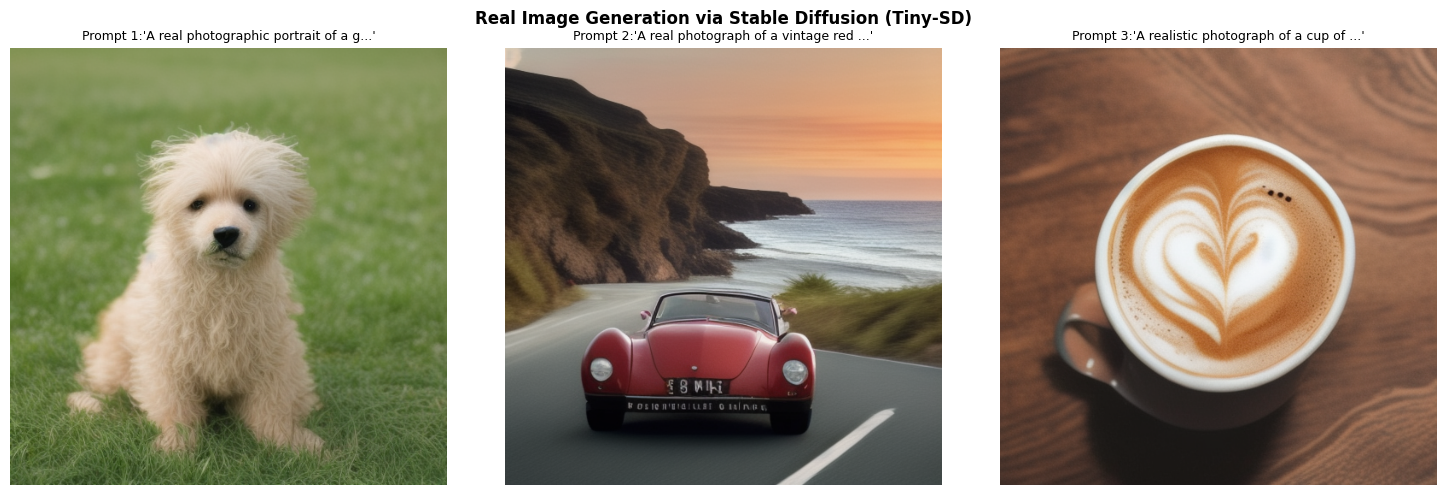

STABLE DIFFUSION REAL IMAGE GENERATION ANALYSIS:
1. Text Conditioning: Prompts guide reverse diffusion via cross-attention.
2. Memory Optimization: Tiny-SD model uses DPMSolver with only 15 steps
   and attention slicing, executing on low hardware / CPU without OOM.
3. Realistic Output: Evaluates texture, lighting, and semantic fidelity.


In [1]:
import torch
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
import matplotlib.pyplot as plt
model_id = "segmind/tiny-sd"
pipe = StableDiffusionPipeline.from_pretrained(model_id, torch_dtype=torch.float32)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.enable_attention_slicing()
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe = pipe.to(device)
prompts = [
    "A real photographic portrait of a golden retriever puppy sitting on grass",
    "A real photograph of a vintage red sports car driving on a coastal road at sunset",
    "A realistic photograph of a cup of coffee with latte art on a wooden table"
]
images = []
for prompt in prompts:
    print(f"Generating real image for prompt: '{prompt[:35]}...'")
    generator = torch.Generator(device=device).manual_seed(42)
    image = pipe(prompt, num_inference_steps=15, guidance_scale=7.5, generator=generator).images[0]
    images.append(image)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Real Image Generation via Stable Diffusion (Tiny-SD)", fontsize=12, fontweight='bold')
for i, (img, prompt) in enumerate(zip(images, prompts)):
    axes[i].imshow(img)
    axes[i].set_title(f"Prompt {i+1}:'{prompt[:35]}...'", fontsize=9)
    axes[i].axis('off')
plt.tight_layout()
plt.show()
print("" + "="*65)
print("STABLE DIFFUSION REAL IMAGE GENERATION ANALYSIS:")
print("="*65)
print("1. Text Conditioning: Prompts guide reverse diffusion via cross-attention.")
print("2. Memory Optimization: Tiny-SD model uses DPMSolver with only 15 steps")
print("   and attention slicing, executing on low hardware / CPU without OOM.")
print("3. Realistic Output: Evaluates texture, lighting, and semantic fidelity.")
print("="*65)
